Dataset shape: (5005, 18)
Training samples: 2648 | Testing samples: 663
Bagging Results
Accuracy : 0.8914027149321267
Precision: 0.9324324324324325
Recall   : 0.9452054794520548
F1 Score : 0.9387755102040817

Boosting (AdaBoost) Results
Accuracy : 0.8989441930618401
Precision: 0.8995363214837713
Recall   : 0.9965753424657534
F1 Score : 0.9455727051177905

Random Forest Results
Accuracy : 0.8974358974358975
Precision: 0.9161290322580645
Recall   : 0.9726027397260274
F1 Score : 0.9435215946843853



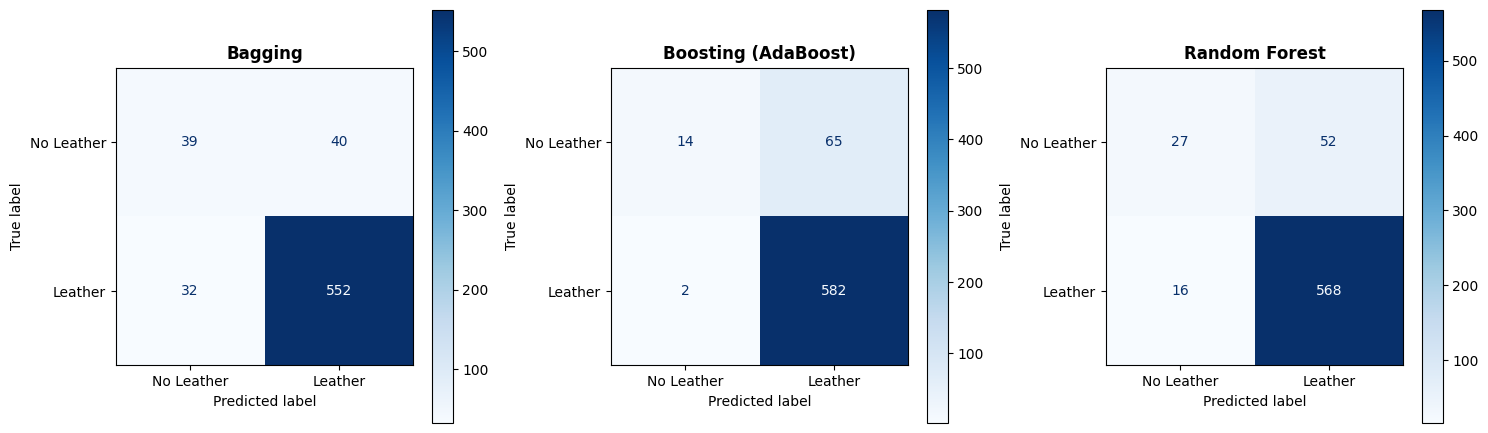

=== BAGGING vs BOOSTING vs RANDOM FOREST COMPARISON ===
              Model  Accuracy  Precision  Recall  F1-Score
            Bagging    0.8914     0.9324  0.9452    0.9388
Boosting (AdaBoost)    0.8989     0.8995  0.9966    0.9456
      Random Forest    0.8974     0.9161  0.9726    0.9435

Best Model by Accuracy: Boosting (AdaBoost) (0.8989)
Best Model by F1-Score: Boosting (AdaBoost) (0.9456)


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,
ConfusionMatrixDisplay)
df = pd.read_csv("/content/cartest.csv")
print("Dataset shape:", df.shape)
df.head(50)
# Select required columns
data = df[['Price', 'Prod. year', 'Levy', 'Engine volume',
'Mileage', 'Cylinders', 'Leather interior']].copy()
# Convert Levy to numeric
data['Levy'] = pd.to_numeric(data['Levy'], errors='coerce')
# Convert Mileage to numeric (remove " km")
data['Mileage'] = data['Mileage'].astype(str).str.replace(' km', '', regex=False)
data['Mileage'] = pd.to_numeric(data['Mileage'], errors='coerce')
# Convert Engine volume to numeric
data['Engine volume'] = pd.to_numeric(data['Engine volume'], errors='coerce')
# Convert Price to numeric
data['Price'] = pd.to_numeric(data['Price'], errors='coerce')
# Convert Leather interior to 0 and 1
data['Leather interior'] = data['Leather interior'].map({'Yes': 1, 'No': 0})
# Remove missing values
data = data.dropna()
# Input features
X = data[['Price', 'Prod. year', 'Levy', 'Engine volume', 'Mileage', 'Cylinders']]
# Target
y = data['Leather interior']
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")
# 1. BAGGING CLASSIFIER
base_model = DecisionTreeClassifier(random_state=42)
bagging_model = BaggingClassifier(estimator=base_model, n_estimators=100, random_state=42)
bagging_model.fit(X_train, y_train)
bagging_pred = bagging_model.predict(X_test)
# 2. BOOSTING CLASSIFIER (AdaBoost with decision stumps)
boosting_model = AdaBoostClassifier(
estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
n_estimators=100,
random_state=42
)
boosting_model.fit(X_train, y_train)
boosting_pred = boosting_model.predict(X_test)
# 3. RANDOM FOREST CLASSIFIER
random_forest = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)
preds = {
"Bagging": bagging_pred,
"Boosting (AdaBoost)": boosting_pred,
"Random Forest": rf_pred,
}
for name, p in preds.items():
 print(f"{name} Results")
 print("Accuracy :", accuracy_score(y_test, p))
 print("Precision:", precision_score(y_test, p))
 print("Recall   :", recall_score(y_test, p))
 print("F1 Score :", f1_score(y_test, p))
 print()






fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, p), display_labels=["No Leather", "Leather"]
    ).plot(ax=ax, cmap="Blues")
    ax.set_title(name, fontweight="bold")

# These should be called OUTSIDE the plot loop
plt.tight_layout()
plt.savefig("exp03_confusion_matrix.png", dpi=300)
plt.show()




comparison = pd.DataFrame({
    "Model": list(preds.keys()),
    "Accuracy": [round(accuracy_score(y_test, p), 4) for p in preds.values()],
    "Precision": [
        round(precision_score(y_test, p), 4) for p in preds.values()
    ],
    "Recall": [round(recall_score(y_test, p), 4) for p in preds.values()],
    "F1-Score": [round(f1_score(y_test, p), 4) for p in preds.values()],
})

# 3. Printing Results
print("=== BAGGING vs BOOSTING vs RANDOM FOREST COMPARISON ===")
print(comparison.to_string(index=False))

best_acc = comparison.loc[comparison["Accuracy"].idxmax()]
best_f1 = comparison.loc[comparison["F1-Score"].idxmax()]

print(
    f"\nBest Model by Accuracy: {best_acc['Model']} ({best_acc['Accuracy']:.4f})"
)
print(f"Best Model by F1-Score: {best_f1['Model']} ({best_f1['F1-Score']:.4f})")




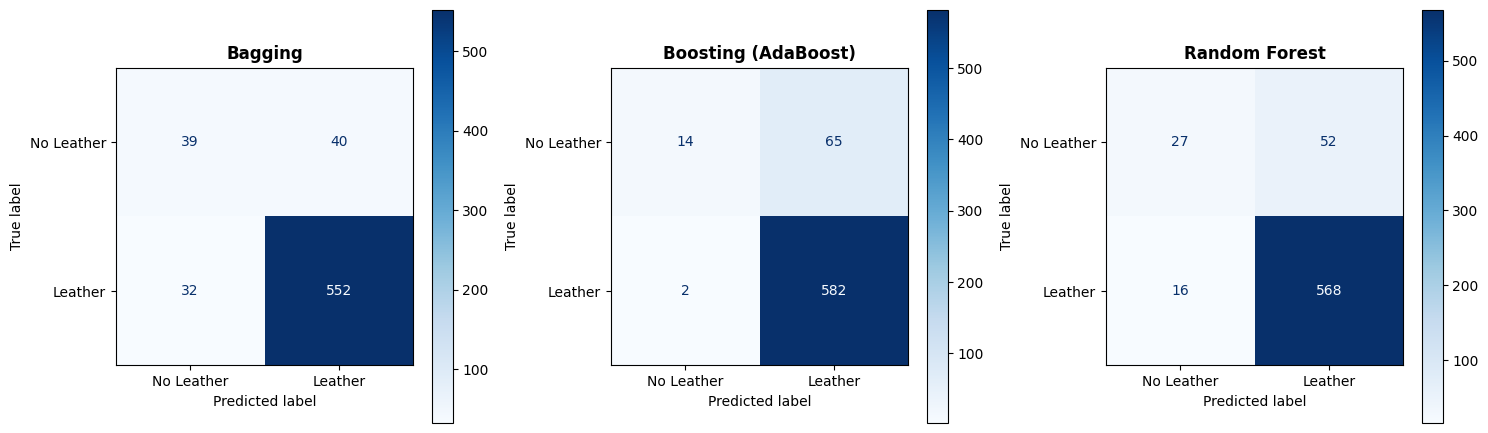

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, p), display_labels=["No Leather", "Leather"]
    ).plot(ax=ax, cmap="Blues")
    ax.set_title(name, fontweight="bold")

# These should be called OUTSIDE the plot loop
plt.tight_layout()
plt.savefig("exp03_confusion_matrix.png", dpi=300)
plt.show()

In [7]:
comparison = pd.DataFrame({
    "Model": list(preds.keys()),
    "Accuracy": [round(accuracy_score(y_test, p), 4) for p in preds.values()],
    "Precision": [
        round(precision_score(y_test, p), 4) for p in preds.values()
    ],
    "Recall": [round(recall_score(y_test, p), 4) for p in preds.values()],
    "F1-Score": [round(f1_score(y_test, p), 4) for p in preds.values()],
})

# 3. Printing Results
print("=== BAGGING vs BOOSTING vs RANDOM FOREST COMPARISON ===")
print(comparison.to_string(index=False))

best_acc = comparison.loc[comparison["Accuracy"].idxmax()]
best_f1 = comparison.loc[comparison["F1-Score"].idxmax()]

print(
    f"\nBest Model by Accuracy: {best_acc['Model']} ({best_acc['Accuracy']:.4f})"
)
print(f"Best Model by F1-Score: {best_f1['Model']} ({best_f1['F1-Score']:.4f})")

=== BAGGING vs BOOSTING vs RANDOM FOREST COMPARISON ===
              Model  Accuracy  Precision  Recall  F1-Score
            Bagging    0.8914     0.9324  0.9452    0.9388
Boosting (AdaBoost)    0.8989     0.8995  0.9966    0.9456
      Random Forest    0.8974     0.9161  0.9726    0.9435

Best Model by Accuracy: Boosting (AdaBoost) (0.8989)
Best Model by F1-Score: Boosting (AdaBoost) (0.9456)
